# 03 · Phase 1: the banker's optimal portfolio
Proposal section 3.2. One question: **what should the 35-year-old Zurich banker hold, once we count his career?**

Strategies compared (proposal 4.1):
* **A** standard mean-variance on the portfolio only (career ignored)
* **B** the "100 − age" rule
* **D** total-wealth portfolio *without* the hedge (only "your job is bond-like, so you can take more risk")
* **C** our total-wealth portfolio (both effects: more risk **and** avoid your own sector)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import career, optimizer as o, risk
from data_loader import load_excess_returns
from estimation import estimate_inputs
from personas import BANKER, CIVIL_SERVANT

p = BANKER
X = load_excess_returns()
m = estimate_inputs(X)
print("Estimation window:", m.sample, "| market risk aversion delta =", round(m.delta, 2))

Estimation window: 2001-10 to 2026-09 (299 months) | market risk aversion delta = 8.27


## 1. Inputs: Black-Litterman expected returns and Ledoit-Wolf risk

In [2]:
inp = pd.DataFrame({
    "market weight": m.w_mkt,
    "expected excess return (BL)": m.mu,
    "historical mean": X[m.assets].mean() * 12,
    "volatility": np.sqrt(np.diag(m.Sigma)),
})
inp.style.format("{:.1%}")

,market weight,expected excess return (BL),historical mean,volatility
world_eq,37.5%,6.8%,6.1%,15.0%
smi,1.2%,4.8%,6.0%,13.2%
eu_banks,0.8%,8.0%,3.7%,25.4%
ubs,0.1%,8.4%,6.3%,30.7%
chf_bonds,1.0%,0.2%,1.6%,4.9%
global_bonds_hedged,53.4%,1.0%,1.7%,6.0%
swiss_re,4.5%,3.4%,7.5%,15.2%
gold,1.5%,1.0%,8.3%,15.2%


**Reading:** Black-Litterman gives each asset the return that makes the world market portfolio optimal.
Gold's 8% historical return (a lucky 25 years) becomes about 1%; that stops the optimizer from chasing past winners.

## 2. One risk aversion for everybody

In [3]:
gamma = o.calibrate_gamma(m)
w0 = o.solve(m, gamma, 0, 0, np.zeros(len(m.assets)), o.Constraints()).weights
print(f"gamma = {gamma:.2f}  ->  a client with no career holds {o.equity_share(w0):.0%} equities")

gamma = 4.33  ->  a client with no career holds 60% equities


## 3. The four strategies for the banker at 35

In [4]:
st = o.client_state(p)
print(f"omega_H = {st.omega_H:.2f}, omega_P = {st.omega_P:.2f}, total wealth W = CHF {st.W:,.0f}")
tab = pd.DataFrame({name: o.strategy(k, p, m, gamma).weights for k, name in
                    [("A", "A standard"), ("B", "B 100-age"), ("D", "D no hedge"), ("C", "C total wealth")]})
tab.loc["cash"] = 1 - tab.sum()
tab.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

omega_H = 0.91, omega_P = 0.05, total wealth W = CHF 2,585,326


,A standard,B 100-age,D no hedge,C total wealth
world_eq,48%,62%,60%,90%
smi,0%,2%,0%,0%
eu_banks,0%,1%,20%,0%
ubs,10%,0%,20%,10%
chf_bonds,0%,1%,0%,0%
global_bonds_hedged,34%,34%,0%,0%
swiss_re,8%,0%,0%,0%
gold,0%,0%,0%,0%
cash,0%,0%,-0%,0%


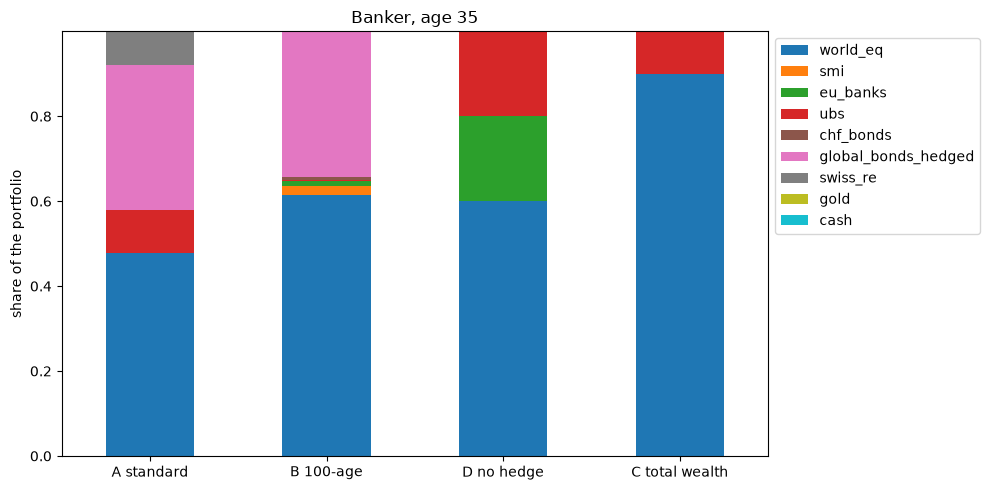

In [5]:
ax = tab.T.plot.bar(stacked=True, figsize=(10, 5), colormap="tab10", rot=0)
ax.set_ylabel("share of the portfolio"); ax.legend(bbox_to_anchor=(1, 1)); ax.set_title("Banker, age 35")
plt.tight_layout()

**Reading:**
* **A → D:** his job is a large bond, so the portfolio drops bonds and takes more equity risk.
* **D → C:** D buys the maximum of banks and UBS, which **doubles the bet he already has through his job**.
  C sells the bank sector to zero and moves it to world equities.
* UBS stays at 10% in every strategy because of the lock-up on his deferred shares.

## 4. Speculative vs hedging demand (no constraints)

In [6]:
sH = career.career_covariance(m.Sigma, p).values
spec, hedge = o.closed_form(m, gamma, st.omega_H, st.omega, sH)
pd.DataFrame({"speculative": spec, "hedging": hedge, "total x*": spec + hedge}).style.format("{:+,.0%}")

,speculative,hedging,total x*
world_eq,"+1,852%",+0%,"+1,852%"
smi,+59%,+0%,+59%
eu_banks,+40%,-710%,-670%
ubs,+5%,+0%,+5%
chf_bonds,+49%,"-7,096%","-7,047%"
global_bonds_hedged,"+2,637%",-0%,"+2,637%"
swiss_re,+222%,+0%,+222%
gold,+74%,-0%,+74%


**Reading:** with omega ≈ 0.96 the unconstrained solution is absurd (thousands of percent long and short).
A real client cannot short or borrow, so the constraints bind (**corner solution**). This is the expected result
of proposal 3.2, and the next table shows what those limits cost.

## 5. What the constraints cost (shadow prices)

In [7]:
costs = o.constraint_costs(p, m, gamma)
costs.style.format({"cost (bp/yr of total wealth)": "{:,.0f}", "cost (CHF/yr)": "CHF {:,.0f}"})

,cost (bp/yr of total wealth),cost (CHF/yr)
constraint,,
No short selling,451,"CHF 116,537"
No borrowing,95,"CHF 24,689"
Position caps,0,CHF 0
Deferred-share lock-up,0,CHF 1


**Reading:** cost = gain in certainty-equivalent return of *total wealth* if the constraint were removed.
"No short selling" is by far the most expensive: the banker would like to short bonds and banks to offset his job, but cannot.

## 6. Where does the risk come from?

In [8]:
rc = pd.DataFrame({name: risk.total_wealth_risk_contributions(o.strategy(k, p, m, gamma).weights, p, st, m)
                   for k, name in [("A", "A standard"), ("C", "C total wealth")]})
rc.loc[["career", "pension"] + m.assets].style.format("{:.1%}")

,A standard,C total wealth
career,99.1%,98.7%
pension,0.0%,0.0%
world_eq,0.6%,1.1%
smi,0.0%,0.0%
eu_banks,0.0%,0.0%
ubs,0.2%,0.2%
chf_bonds,0.0%,0.0%
global_bonds_hedged,0.1%,0.0%
swiss_re,0.1%,0.0%
gold,0.0%,0.0%


In [9]:
pr = risk.portfolio_risk_contributions(o.strategy("C", p, m, gamma).weights, m)
print("What a standard tool shows (portfolio only), strategy C:")
pr[pr > 0.001].map("{:.0%}".format)

What a standard tool shows (portfolio only), strategy C:


world_eq    86%
ubs         14%
Name: risk share, dtype: str

**Reading:** a standard tool says "world equities are 90% of your risk". On total wealth, **about 99% of the banker's
risk is his career**; the portfolio can only change a small part of it, and C changes it in the right direction.

## 7. Preview of the glide path (Phase 2)

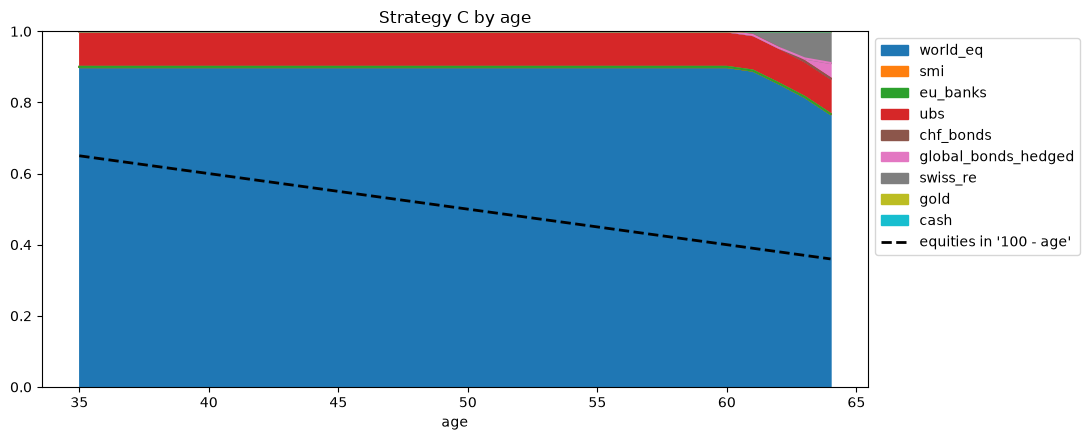

In [10]:
ages = range(p.age, p.retirement_age)
path = pd.DataFrame({a: o.strategy("C", p, m, gamma, age=a).weights for a in ages}).T
path["cash"] = (1 - path.sum(axis=1)).clip(lower=0)
ax = path.plot.area(figsize=(11, 4.5), colormap="tab10")
b = pd.Series({a: o.equity_share(o.rule_100_minus_age(a, m).weights) for a in ages})
b.plot(ax=ax, color="black", ls="--", lw=2, label="equities in '100 - age'")
ax.set_ylim(0, 1); ax.legend(bbox_to_anchor=(1, 1)); ax.set_xlabel("age"); ax.set_title("Strategy C by age")
plt.tight_layout()

**Reading:** while omega is high the solution stays at the corner (all equities, no banks); as the career shrinks
the portfolio becomes interior and starts holding bonds and real estate near retirement.

## 8. Banker vs civil servant

In [11]:
cmp = pd.DataFrame({q.name: o.strategy("C", q, m, gamma, cons=o.Constraints()).weights
                    for q in (BANKER, CIVIL_SERVANT)})
cmp.loc["cash"] = 1 - cmp.sum()
cmp.style.format("{:.0%}")   # same model, different job -> different portfolio

,Zurich banker,Civil servant
world_eq,94%,60%
smi,0%,0%
eu_banks,0%,20%
ubs,6%,20%
chf_bonds,0%,0%
global_bonds_hedged,0%,0%
swiss_re,0%,0%
gold,0%,0%
cash,0%,-0%


## 9. Optional: a client view (Black-Litterman)

In [12]:
views = [{"long": "smi", "short": "world_eq", "q": 0.02}]   # "Swiss stocks beat world stocks by 2% a year"
mv = estimate_inputs(X, views=views)
pd.DataFrame({"prior pi": m.mu, "with view": mv.mu}).style.format("{:.2%}")

,prior pi,with view
world_eq,6.78%,5.26%
smi,4.81%,5.28%
eu_banks,7.98%,6.74%
ubs,8.38%,7.56%
chf_bonds,0.25%,0.28%
global_bonds_hedged,1.04%,1.22%
swiss_re,3.41%,3.50%
gold,0.95%,0.77%
